# 03 — Orange Belgium causal-retention audit

**Decision question:** trong high-risk pool đã được hệ thống Orange chọn, target assignment có làm giảm
churn hai tháng và ranking nào nên dùng khi capacity hữu hạn?

Notebook này tách bốn việc: kiểm data/experiment, ước lượng average effect và power, chọn policy bằng
development OOF, rồi đọc đúng một locked holdout. Positive uplift luôn có nghĩa `Y(0)-Y(1)` — churn
được ngăn. Kết quả là intention-to-treat, không phải effect của một offer cụ thể.

Nguồn: [OpenML 45580](https://www.openml.org/search?type=data&id=45580) và
[dataset paper](https://arxiv.org/abs/2312.07206). Raw data CC BY-NC-ND không được commit.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from telco_churn.orange_data import DEFAULT_PATH, EXPECTED_MD5, fetch_orange, file_md5, load_orange
from telco_churn.uplift import ate_with_wald_interval

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent

DATA = ROOT / DEFAULT_PATH
REPORT = ROOT / "reports/uplift"
if not DATA.exists():
    fetch_orange(DATA)

frame = load_orange(DATA)
print({"rows": len(frame), "columns": frame.shape[1], "md5": file_md5(DATA)})

{'rows': 11896, 'columns': 180, 'md5': 'bd328613c1c4ef793ab04cd4dd1c6db0'}


## 1. Data contract và structural audit

Không có customer ID hoặc campaign timestamp công khai. `row_id` dưới đây chỉ là source-order key được
an toàn bởi checksum. Do đó không được group/time split hoặc suy ra khách nào lặp lại.

In [2]:
audit = pd.Series({
    "rows": len(frame),
    "numeric_PC": sum(c.startswith("PC") for c in frame),
    "categorical_FACTOR": sum(c.startswith("FACTOR") for c in frame),
    "missing_cells": int(frame.isna().sum().sum()),
    "duplicate_rows": int(frame.duplicated().sum()),
    "treatment_rate": frame["t"].mean(),
    "churn_rate": frame["y"].mean(),
})
display(audit.to_frame("value"))
assert file_md5(DATA) == EXPECTED_MD5
assert frame.shape == (11_896, 180)
assert not frame.isna().any().any()

,value
rows,11896.000000
numeric_PC,160.000000
categorical_FACTOR,18.000000
missing_cells,0.000000
duplicate_rows,0.000000
treatment_rate,0.757397
churn_rate,0.034297


## 2. Treatment × outcome và average effect

Chênh lệch raw rate chỉ hợp lệ cho eligible high-risk pool. CI và event count phải đứng cạnh point
estimate vì outcome chỉ khoảng 3,4%.

In [3]:
arm_table = frame.groupby("t")["y"].agg(n="size", churn_events="sum", churn_rate="mean")
display(arm_table)
ate = ate_with_wald_interval(frame["y"].to_numpy(), frame["t"].to_numpy())
display(pd.Series(ate).to_frame("value"))

,n,churn_events,churn_rate
t,,,
0,2886,105,0.036383
1,9010,303,0.033629


,value
control_churn_rate,0.036383
treated_churn_rate,0.033629
ate_prevented_churn,0.002753
standard_error,0.003970
ci95_low,-0.005027
ci95_high,0.010534
control_n,2886.000000
treated_n,9010.000000


## 3. Power: effect nhỏ hơn độ phân giải của experiment

In [4]:
profile = json.loads((REPORT / "data_profile.json").read_text(encoding="utf-8"))
power = pd.Series(profile["power"])
display(power.to_frame("value"))
print(
    f"Observed effect = {power['ate_prevented_churn']:.3%}; "
    f"80% power MDE = {power['mde_80pct_power_two_sided_alpha_0_05']:.3%}; "
    f"required N at observed effect ≈ {int(power['required_n_for_observed_effect_80pct_power']):,}."
)

,value
control_churn_rate,0.036383
treated_churn_rate,0.033629
ate_prevented_churn,0.002753
standard_error,0.003970
ci95_low,-0.005027
ci95_high,0.010534
control_n,2886.000000
treated_n,9010.000000
treatment_fraction,0.757397
mde_80pct_power_two_sided_alpha_0_05,0.011120


Observed effect = 0.275%; 80% power MDE = 1.112%; required N at observed effect ≈ 194,060.


## 4. Assignment balance diagnostics

Max SMD không phải global randomization test khi có 178 feature/many levels. Dùng để tìm data join lỗi,
không cherry-pick một feature hậu nghiệm. Paper gốc báo classifier two-sample permutation p=0,26.

In [5]:
numeric_balance = pd.read_csv(REPORT / "balance_numeric.csv")
categorical_balance = pd.read_csv(REPORT / "balance_categorical.csv")
display(numeric_balance.head(10))
display(categorical_balance.head(10))

,feature,control_mean,treated_mean,standardized_mean_difference,absolute_smd
0,PC8,0.307332,-0.098442,-0.219743,0.219743
1,PC28,-0.149423,0.047862,0.167762,0.167762
2,PC1,-0.390214,0.124990,0.128389,0.128389
3,PC2,-0.276218,0.088476,0.110840,0.110840
4,PC7,-0.172760,0.055337,0.110770,0.110770
5,PC12,-0.123599,0.039590,0.106420,0.106420
6,PC4,0.197510,-0.063265,-0.104576,0.104576
7,PC132,0.012803,-0.004101,-0.099027,0.099027
8,PC20,0.106222,-0.034024,-0.097996,0.097996
9,PC19,-0.090491,0.028985,0.087349,0.087349


,feature,level,control_share,treated_share,absolute_share_difference
0,FACTOR18,V7,0.319473,0.495671,0.176198
1,FACTOR4,V10,0.127859,0.249279,0.121420
2,FACTOR18,V2,0.248094,0.175805,0.072290
3,FACTOR18,V4,0.334719,0.267370,0.067350
4,FACTOR4,V12,0.329175,0.262930,0.066245
5,FACTOR2,V10,0.630631,0.693119,0.062488
6,FACTOR4,V7,0.147609,0.094562,0.053048
7,FACTOR6,V10,0.041580,0.087791,0.046211
8,FACTOR6,V20,0.243936,0.199889,0.044047
9,FACTOR12,V3,0.169439,0.209989,0.040550


## 5. Frozen split và leakage boundary

Split 80/20 stratify joint `(t,y)`. Tất cả preprocessing/model/budget selection dùng development OOF;
holdout không quyết định model. Public data thiếu time nên đây vẫn không phải temporal validation.

In [6]:
manifest = pd.read_csv(REPORT / "split_manifest.csv")
display(pd.crosstab([manifest["split"], manifest["treatment"]], manifest["outcome"], margins=True))
print("manifest_sha256:", profile["manifest_sha256"])

outcome                    0    1    All
split       treatment                   
development 0           2225   84   2309
            1           6965  242   7207
test        0            556   21    577
            1           1742   61   1803
All                    11488  408  11896

manifest_sha256: e2828178d09952fe97d3a360a7511ae75f600949546ab4aaa1ffc06862f4efe3


## 6. Development OOF benchmark

Risk, S-, T- và DR-learners được so bằng cùng folds. AUUC/Qini dùng DR score để giảm variance; IPW được
giữ như sensitivity check. Convention nằm trong `telco_churn.uplift.curve_metrics`.

In [7]:
oof = pd.read_csv(REPORT / "oof_model_comparison.csv")
display(oof.sort_values("qini_dr", ascending=False))

budget = pd.read_csv(REPORT / "oof_budget_metrics.csv")
display(
    budget.sort_values("dr_incremental_churns_prevented", ascending=False)
          .head(12)[["model", "budget_fraction", "dr_uplift", "dr_ci95_low", "dr_ci95_high",
                     "dr_incremental_churns_prevented"]]
)

,model,qini_ipw,auuc_ipw,qini_dr,auuc_dr
0,dr_hgb,0.001657,0.003057,0.002020,0.002040
1,risk_logistic,0.003135,0.004536,0.001634,0.001654
2,risk_rf,0.001358,0.002758,0.000015,0.000035
3,s_hgb,0.003783,0.005184,-0.000206,-0.000186
4,x_hgb,-0.000615,0.000786,-0.000477,-0.000457
5,t_rf,-0.000386,0.001014,-0.000869,-0.000849
6,t_logistic,-0.001585,-0.000184,-0.001097,-0.001077
7,random,-0.005093,-0.003692,-0.005024,-0.005004


,model,budget_fraction,dr_uplift,dr_ci95_low,dr_ci95_high,dr_incremental_churns_prevented
5,risk_logistic,0.3,0.014979,-0.009769,0.041220,42.763671
20,dr_hgb,0.3,0.012294,-0.006760,0.031274,35.098941
22,x_hgb,0.2,0.012874,-0.012228,0.037229,24.512014
19,dr_hgb,0.2,0.011117,-0.012531,0.036078,21.165849
18,dr_hgb,0.1,0.021567,-0.018376,0.060264,20.532171
3,risk_logistic,0.1,0.014346,-0.042360,0.070880,13.657049
7,risk_rf,0.2,0.006111,-0.027241,0.040418,11.635841
23,x_hgb,0.3,0.003932,-0.014475,0.023732,11.224805
15,s_hgb,0.1,0.005088,-0.020694,0.032356,4.844241
4,risk_logistic,0.2,0.002324,-0.031360,0.035872,4.425477


## 7. Locked holdout decision

In [8]:
locked = json.loads((REPORT / "locked_policy_decision.json").read_text(encoding="utf-8"))
display(pd.Series({k: v for k, v in locked.items() if k != "gates"}).to_frame("value"))
display(pd.Series(locked["gates"]).to_frame("pass"))
assert locked["test_decision"] == 'no_launch'

,value
model,risk_logistic
budget_fraction,0.3
selected_on,development OOF only
development_dr_incremental_churns_prevented,42.763671
test_dr_uplift,0.033309
test_ci95_low,-0.015071
test_ci95_high,0.08269
test_ipw_uplift,0.010761
test_ipw_ci95_low,-0.035866
test_ipw_ci95_high,0.060188


,pass
positive_dr_ci_lower,False
positive_ipw_ci_lower,False
positive_qini,True
at_least_20_control_churn_events,False
at_least_20_treated_churn_events,True


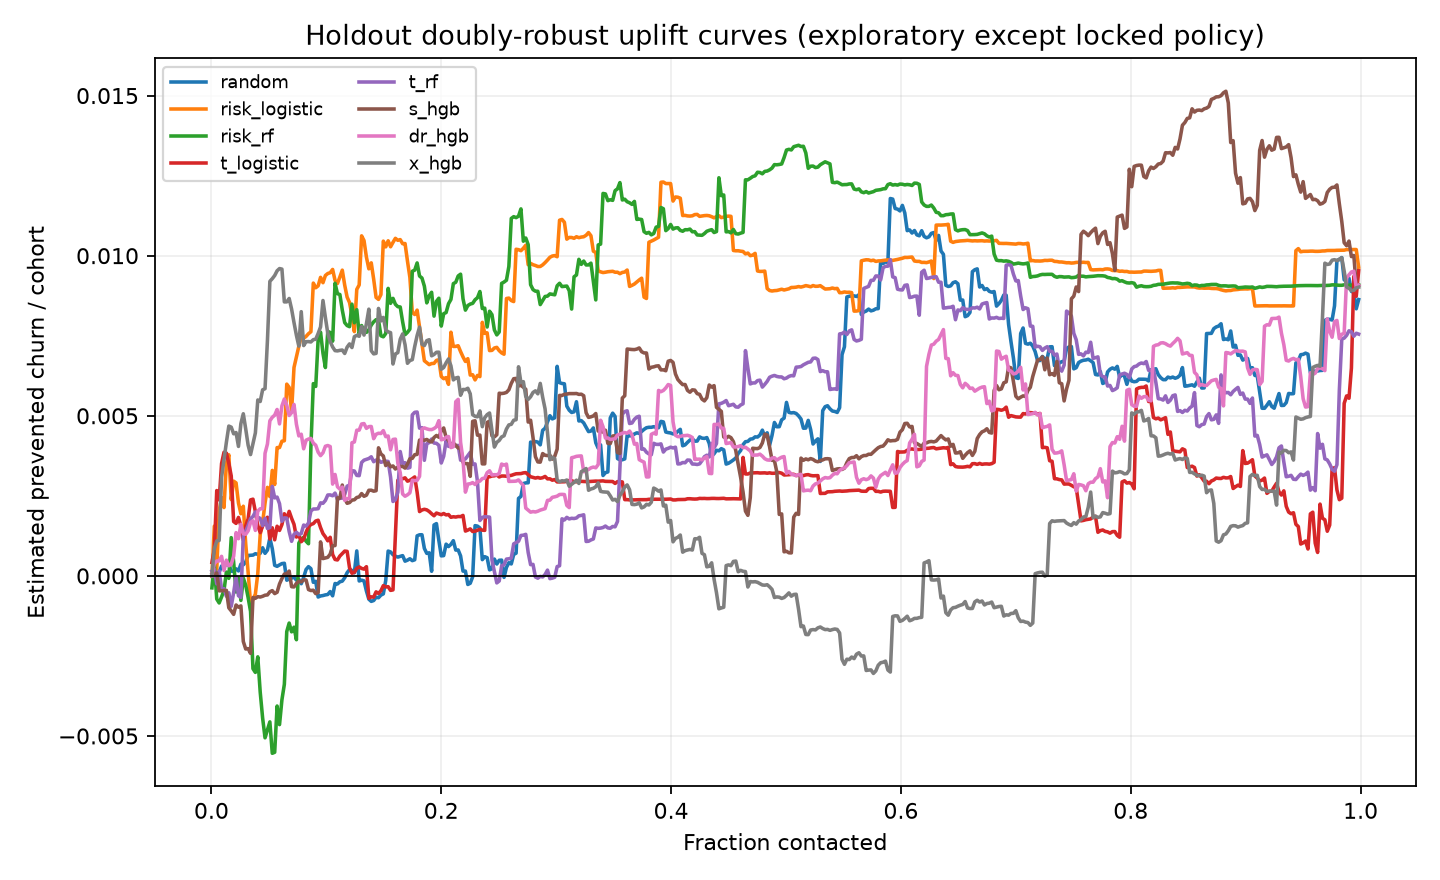

In [9]:
display(Image(filename=str(REPORT / "figures/holdout_uplift_curves.png")))

## 8. Kết luận không được sửa sau test

- Qini dương không đủ: DR và IPW CI đều qua 0, control chỉ có 15 churn events trong locked segment.
- Không có margin/contact/offer cost nên không báo profit; chỉ có break-even `uplift × value`.
- Không diễn giải PC/factor importance thành churn driver.
- Next action không phải thêm model tùy ý: tăng randomized control/events, chuẩn hóa offer, log delivery,
  cost, margin, campaign/customer/time IDs và chạy rolling evaluation.

Xem report đầy đủ ở `reports/uplift/CAUSAL_BENCHMARK_REPORT.md`.